# Water Segmentation with a Pretrained Encoder (Week 2)

Pretrained ResNet U-Net (`segmentation-models-pytorch`) with the first convolution adapted to N channels, fine-tuned on the water dataset and compared with the scratch U-Net from Week 1. Same data pipeline, features, seed and split as the scratch U-Net.

## 1. Setup

In [1]:
import os, glob, random, math, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from scipy.ndimage import uniform_filter, label as cc_label
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

try:
    import segmentation_models_pytorch as smp
except ImportError:
    %pip install -q segmentation-models-pytorch
    import segmentation_models_pytorch as smp

warnings.filterwarnings("ignore", category=UserWarning)

DATA_DIR = "/kaggle/input/datasets/shahdelsawy/sattlite-segmentation/data"
SEED = 42
BATCH_SIZE = 32
EPOCHS = 150
LR_ENCODER = 3e-4
LR_DECODER = 1e-3
EMA_DECAY = 0.99
SEEDS_EXTRA = [43, 44]
PIXEL_SIZE = 30.0

SCRATCH = {"val": {"iou": 0.7646, "f1": 0.8666, "precision": 0.8413, "recall": 0.8934},
         "test": {"iou": 0.8004, "f1": 0.8891, "precision": 0.8684, "recall": 0.9109}}
SCRATCH_RECALL_BY_SIZE = {"<=10": 0.344, "11-50": 0.518, "51-200": 0.549, "201-1000": 0.652, ">1000": 0.904}

INPUTS = [
    dict(name="12ch average", feature_set="all_12", strategy="average"),
    dict(name="12ch zero-init", feature_set="all_12", strategy="zero"),
    dict(name="16ch zero-init", feature_set="plus_terrain_landcover", strategy="zero"),
]
LEAN = dict(attention=False, ema=False, loss="dice", scale=1)
STEPS = [
    ("+ Tversky loss", {}, {"loss": "tversky"}),
    ("+ attention + EMA", {}, {"attention": True, "ema": True}),
    ("+ 2x input upscaling", {}, {"scale": 2}),
    ("+ ResNet50 encoder", {"encoder": "resnet50"}, {}),
]

BANDS = ["Coastal aerosol", "Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2",
         "QA band", "MERIT DEM", "Copernicus DEM", "ESA WorldCover", "Water occurrence"]
INDICES = ["NDWI", "MNDWI", "NDVI", "AWEI"]
ANCILLARY = ["Copernicus DEM", "Slope", "Relief", "Water occurrence", "WC water", "WC wetland"]
EXTRA = ["Slope", "Relief", "WC water", "WC wetland"]
BINARY = ["WC water", "WC wetland"]
NAMES = BANDS + INDICES + EXTRA

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]
print(device, "| smp", smp.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 1.0 MB/s eta 0:00:0000:010:010m
Note: you may need to restart the kernel to use updated packages.
cuda | smp 0.5.0


## 2. Load data

In [2]:
image_paths = sorted(glob.glob(f"{DATA_DIR}/images/*.tif"))
label_dir = f"{DATA_DIR}/labels"

N, H, W, C = len(image_paths), 128, 128, 12
X = np.zeros((N, C + len(INDICES) + len(EXTRA), H, W), dtype=np.float32)
Y = np.zeros((N, H, W), dtype=np.float32)

for i, path in enumerate(tqdm(image_paths)):
    name = os.path.splitext(os.path.basename(path))[0]
    img = tifffile.imread(path)
    assert img.shape == (H, W, C), img.shape
    X[i, :C] = np.nan_to_num(img.transpose(2, 0, 1))
    Y[i] = np.array(Image.open(f"{label_dir}/{name}.png")) > 0

print(N, "images", X.shape, Y.shape)

  0%|          | 0/306 [00:00<?, ?it/s]

306 images (306, 20, 128, 128) (306, 128, 128)


## 3. Data exploration

water pixels 25.98% | images without water 14.71%
MERIT DEM minimum -9999 (no-data value) | water occurrence maximum 111


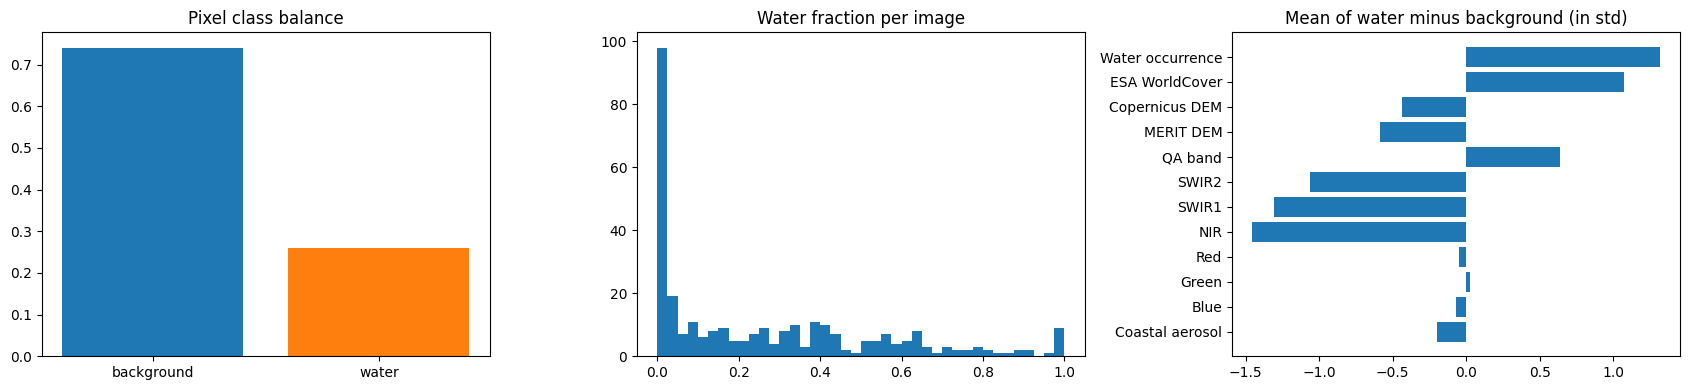

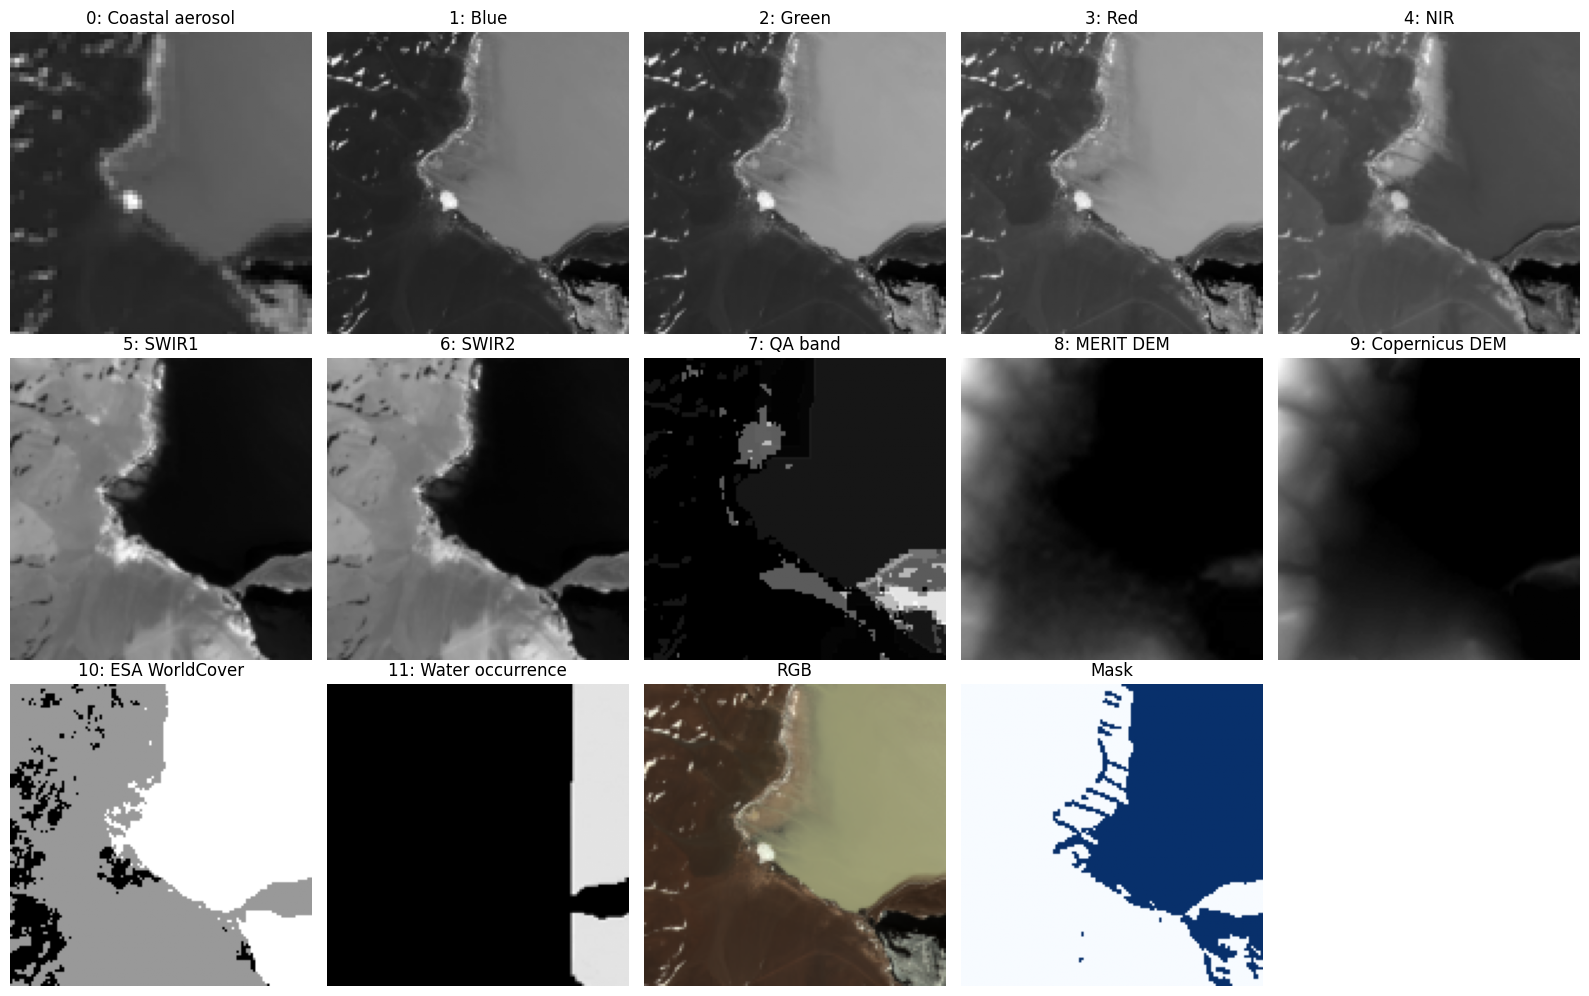

In [3]:
water_ratio = Y.mean()
per_image = Y.mean(axis=(1, 2))
print(f"water pixels {water_ratio:.2%} | images without water {(per_image == 0).mean():.2%}")
print(f"MERIT DEM minimum {X[:, 8].min():.0f} (no-data value) | water occurrence maximum {X[:, 11].max():.0f}")

separation = []
for c in range(C):
    v = np.clip(X[:, c], *np.percentile(X[:, c], [1, 99]))
    separation.append((v[Y > 0.5].mean() - v[Y < 0.5].mean()) / (v.std() + 1e-8))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].bar(["background", "water"], [1 - water_ratio, water_ratio], color=COLORS[:2])
axes[0].set_title("Pixel class balance")
axes[1].hist(per_image, bins=40)
axes[1].set_title("Water fraction per image")
axes[2].barh(BANDS, separation)
axes[2].set_title("Mean of water minus background (in std)")
plt.tight_layout()
plt.show()

k = int(np.argmin(np.abs(per_image - 0.4)))
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for c in range(C):
    axes.flat[c].imshow(X[k, c], cmap="gray")
    axes.flat[c].set_title(f"{c}: {BANDS[c]}")
rgb = X[k, [3, 2, 1]].transpose(1, 2, 0)
axes.flat[12].imshow((rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6))
axes.flat[12].set_title("RGB")
axes.flat[13].imshow(Y[k], cmap="Blues")
axes.flat[13].set_title("Mask")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Feature engineering

| Channel | Decision |
|---|---|
| Coastal aerosol, QA band, MERIT DEM | Drop: aerosol band correlated with Blue, bit flags, near-duplicate of Copernicus DEM with a -9999 no-data value |
| Blue, Green, Red, NIR, SWIR1, SWIR2 | Keep: water absorbs NIR and SWIR, Green is needed for the water indices |
| Copernicus DEM, Water occurrence | Keep: water lies in low flat areas, occurrence is the historical water frequency |
| ESA WorldCover | One-hot water and wetland channels instead of raw class codes |
| NDWI, MNDWI, NDVI, AWEI | Add: spectral water and vegetation indices |
| Slope, Relief | Add: flatness and height above the local 15 x 15 mean |

In [4]:
def norm_diff(a, b):
    return (a - b) / (a + b + 1e-6)

green, red, nir, swir1, swir2 = (X[:, i] for i in (2, 3, 4, 5, 6))
X[:, 12] = norm_diff(green, nir)
X[:, 13] = norm_diff(green, swir1)
X[:, 14] = norm_diff(nir, red)
X[:, 15] = 4 * (green - swir1) - (0.25 * nir + 2.75 * swir2)
del green, red, nir, swir1, swir2

dem = X[:, BANDS.index("Copernicus DEM")].copy()
gy, gx = np.gradient(dem, PIXEL_SIZE, axis=(1, 2))
X[:, NAMES.index("Slope")] = np.degrees(np.arctan(np.hypot(gx, gy)))
X[:, NAMES.index("Relief")] = dem - uniform_filter(dem, size=(1, 15, 15), mode="reflect")
del dem, gx, gy

LC = np.rint(X[:, BANDS.index("ESA WorldCover")]).astype(np.int16)
X[:, NAMES.index("WC water")] = LC == 80
X[:, NAMES.index("WC wetland")] = np.isin(LC, (90, 95))

## 5. Split and normalization

In [5]:
perm = np.random.permutation(N)
n_train, n_val = int(0.70 * N), int(0.15 * N)
train_idx = perm[:n_train]
val_idx = perm[n_train:n_train + n_val]
test_idx = perm[n_train + n_val:]
print("train / val / test:", len(train_idx), len(val_idx), len(test_idx))

channel_stats = []
for c in range(X.shape[1]):
    if NAMES[c] in BINARY:
        channel_stats.append((0, 1, 0, 1))
        continue
    low, high = np.percentile(X[train_idx[:500], c], [1, 99])
    train_values = np.clip(X[train_idx, c], low, high)
    mean, std = train_values.mean(), train_values.std() + 1e-8
    X[:, c] = (np.clip(X[:, c], low, high) - mean) / std
    channel_stats.append((low, high, mean, std))

pd.DataFrame(channel_stats, index=NAMES, columns=["low", "high", "mean", "std"]).to_csv("normalization_stats.csv")

gt_val, gt_test = Y[val_idx] > 0.5, Y[test_idx] > 0.5

train / val / test: 214 45 47


## 6. Channel importance

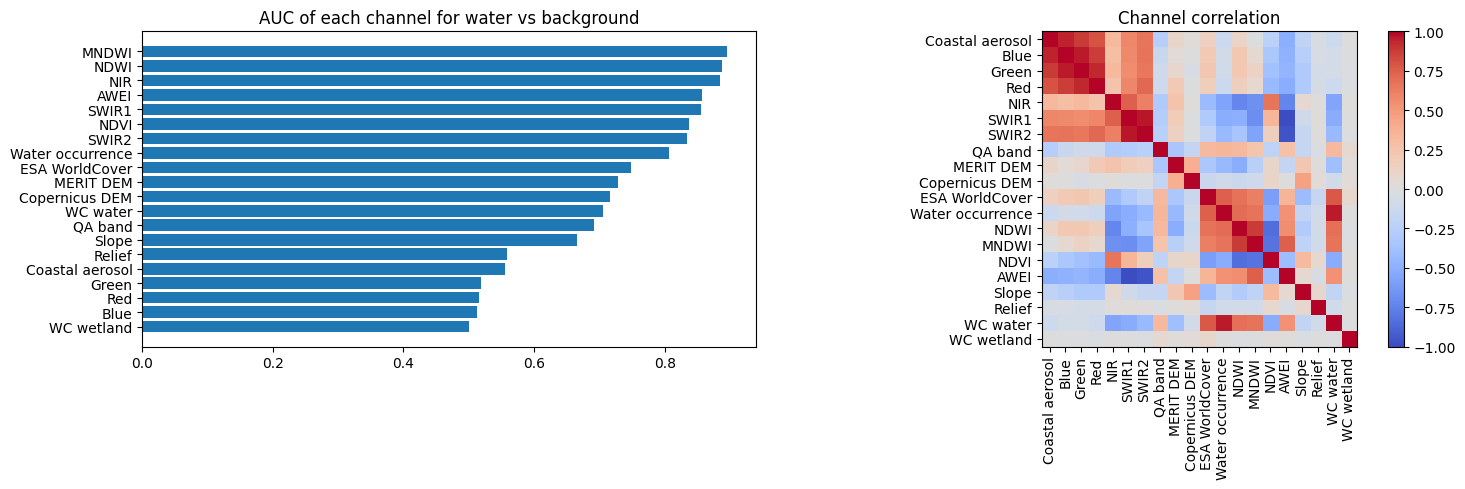

In [6]:
rng = np.random.default_rng(0)
sample_images = rng.choice(train_idx, size=min(300, len(train_idx)), replace=False)
pixel_ids = rng.integers(0, H * W, size=(len(sample_images), 400))
xs = np.concatenate([X[i].reshape(len(NAMES), -1)[:, p] for i, p in zip(sample_images, pixel_ids)], axis=1).T
ys = np.concatenate([Y[i].reshape(-1)[p] for i, p in zip(sample_images, pixel_ids)])

auc = np.array([max(a, 1 - a) for a in (roc_auc_score(ys, xs[:, c]) for c in range(len(NAMES)))])
order = np.argsort(auc)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh([NAMES[i] for i in order], auc[order])
axes[0].set_title("AUC of each channel for water vs background")
im = axes[1].imshow(np.corrcoef(xs.T), cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(NAMES)))
axes[1].set_xticklabels(NAMES, rotation=90)
axes[1].set_yticks(range(len(NAMES)))
axes[1].set_yticklabels(NAMES)
axes[1].set_title("Channel correlation")
plt.colorbar(im, ax=axes[1])
plt.tight_layout()
plt.show()

def idx(names):
    return [NAMES.index(n) for n in names]

core = ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"] + INDICES
FEATURE_SETS = {
    "all_12": list(range(12)),
    "plus_terrain_landcover": idx(core + ["Copernicus DEM", "Slope", "Relief", "Water occurrence", "WC water", "WC wetland"]),
}

## 7. Pretrained encoder and first-layer adaptation

ResNet encoders (ResNet34 here, ResNet50 as an upgrade) are pretrained on 3-channel ImageNet photos, so their low-level edge and texture filters transfer but the first convolution expects 3 channels. Two ways to adapt it to N channels:

- **average:** the three RGB filters are averaged, repeated on all N channels and scaled by 3 / N
- **zero-init:** the RGB filters go to the Red, Green and Blue channels and all other channels start at zero, so the network starts as the pretrained RGB model

In [7]:
def find_first_conv(model):
    for name, module in model.encoder.named_modules():
        if isinstance(module, nn.Conv2d) and module.in_channels == 3:
            return name, module
    raise RuntimeError("no 3-channel input convolution found")


def adapt_first_conv(model, in_channels, strategy, rgb_positions):
    name, conv = find_first_conv(model)
    w = conv.weight.data
    if strategy == "average":
        new_w = w.mean(dim=1, keepdim=True).repeat(1, in_channels, 1, 1) * (3.0 / in_channels)
    else:
        new_w = torch.zeros(w.shape[0], in_channels, *w.shape[2:], dtype=w.dtype)
        for src, dst in enumerate(rgb_positions):
            new_w[:, dst] = w[:, src]
    new_conv = copy.deepcopy(conv)
    new_conv.in_channels = in_channels
    new_conv.weight = nn.Parameter(new_w.clone())
    parent = model.encoder
    parts = name.split(".")
    for p in parts[:-1]:
        parent = getattr(parent, p)
    setattr(parent, parts[-1], new_conv)


class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=4):
        super().__init__()
        hidden = max(channels // reduction, 2)
        self.fc = nn.Sequential(nn.Linear(channels, hidden), nn.ReLU(), nn.Linear(hidden, channels), nn.Sigmoid())
        nn.init.zeros_(self.fc[2].weight)
        nn.init.constant_(self.fc[2].bias, 3.0)

    def forward(self, x):
        return x * self.fc(x.mean(dim=(2, 3)))[:, :, None, None]


class WithAttention(nn.Module):
    def __init__(self, net, channels):
        super().__init__()
        self.attn, self.net = ChannelAttention(channels), net

    @property
    def encoder(self):
        return self.net.encoder

    def forward(self, x):
        return self.net(self.attn(x))


class Upscaled(nn.Module):
    def __init__(self, net, scale):
        super().__init__()
        self.net, self.scale = net, scale

    @property
    def encoder(self):
        return self.net.encoder

    def forward(self, x):
        return F.avg_pool2d(self.net(F.interpolate(x, scale_factor=self.scale, mode="bilinear", align_corners=False)), self.scale)


def build_model(cfg, channels, recipe):
    try:
        net = smp.Unet(encoder_name=cfg["encoder"], encoder_weights="imagenet", in_channels=3, classes=1)
    except Exception as e:
        raise RuntimeError("Could not download ImageNet weights. Turn internet on and run again.") from e
    rgb = [channels.index(NAMES.index(n)) for n in ("Red", "Green", "Blue")]
    adapt_first_conv(net, len(channels), cfg["strategy"], rgb)
    if recipe["scale"] > 1:
        net = Upscaled(net, recipe["scale"])
    return WithAttention(net, len(channels)) if recipe["attention"] else net


for strategy in ("average", "zero"):
    cfg = {"encoder": "resnet34", "strategy": strategy}
    m = build_model(cfg, FEATURE_SETS["all_12"], LEAN)
    first = next(mod for mod in m.encoder.modules() if isinstance(mod, nn.Conv2d))
    print(f"{strategy}: first conv {tuple(first.weight.shape)} | output {tuple(m(torch.randn(2, 12, H, W)).shape)} | {sum(p.numel() for p in m.parameters()) / 1e6:.1f} M parameters")
del m

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

average: first conv (64, 12, 7, 7) | output (2, 1, 128, 128) | 24.5 M parameters
zero: first conv (64, 12, 7, 7) | output (2, 1, 128, 128) | 24.5 M parameters


## 8. Training utilities

In [8]:
def bce_dice(logits, target):
    bce = F.binary_cross_entropy_with_logits(logits, target)
    prob = torch.sigmoid(logits)
    inter = (prob * target).sum(dim=(1, 2, 3))
    return bce + 1 - ((2 * inter + 1) / (prob.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3)) + 1)).mean()


def bce_tversky(logits, target, alpha=0.3, beta=0.7):
    bce = F.binary_cross_entropy_with_logits(logits, target)
    prob = torch.sigmoid(logits)
    tp = (prob * target).sum(dim=(1, 2, 3))
    fp = (prob * (1 - target)).sum(dim=(1, 2, 3))
    fn = ((1 - prob) * target).sum(dim=(1, 2, 3))
    return bce + 1 - ((tp + 1) / (tp + alpha * fp + beta * fn + 1)).mean()


LOSSES = {"dice": bce_dice, "tversky": bce_tversky}


class EMA:
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay

    @torch.no_grad()
    def update(self, model, step):
        d = min(self.decay, (1 + step) / (10 + step))
        for e, p in zip(self.module.parameters(), model.parameters()):
            e.lerp_(p, 1 - d)
        for e, b in zip(self.module.buffers(), model.buffers()):
            e.copy_(b)


def make_loader(indices, channels, shuffle):
    x = torch.from_numpy(X[np.ix_(indices, channels)])
    y = torch.from_numpy(Y[indices]).unsqueeze(1)
    return DataLoader(TensorDataset(x, y), batch_size=BATCH_SIZE, shuffle=shuffle)


@torch.no_grad()
def predict_tensor(model, x):
    model.eval()
    return torch.cat([torch.sigmoid(model(b.to(device))).cpu() for b in x.split(BATCH_SIZE)]).squeeze(1).numpy()


def predict_proba(model, indices, channels):
    return predict_tensor(model, torch.from_numpy(X[np.ix_(indices, channels)]))


def scores(tp, fp, fn):
    precision, recall = tp / (tp + fp + 1e-9), tp / (tp + fn + 1e-9)
    return {"iou": tp / (tp + fp + fn + 1e-9), "precision": precision, "recall": recall,
            "f1": 2 * precision * recall / (precision + recall + 1e-9)}


def metrics(prob, gt, threshold=0.5):
    pred = prob > threshold
    return scores((pred & gt).sum(), (pred & ~gt).sum(), (~pred & gt).sum())


@torch.no_grad()
def val_pass(model, loader, loss_fn):
    model.eval()
    tp = fp = fn = tn = loss = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss += loss_fn(logits, y).item() * len(x)
        pred, gt = logits > 0, y > 0.5
        tp += (pred & gt).sum().item()
        fp += (pred & ~gt).sum().item()
        fn += (~pred & gt).sum().item()
        tn += (~pred & ~gt).sum().item()
    s = scores(tp, fp, fn)
    return {"val_loss": loss / len(loader.dataset), "val_acc": (tp + tn) / (tp + fp + fn + tn), "val_iou": s["iou"], "val_f1": s["f1"]}


def train(cfg, recipe, tag, seed=SEED):
    channels = FEATURE_SETS[cfg["feature_set"]]
    train_loader, val_loader = make_loader(train_idx, channels, True), make_loader(val_idx, channels, False)
    random.seed(seed)
    torch.manual_seed(seed)
    model = build_model(cfg, channels, recipe).to(device)
    ema = EMA(model, EMA_DECAY) if recipe["ema"] else None
    eval_model = ema.module if ema else model
    loss_fn = LOSSES[recipe["loss"]]

    enc = list(model.encoder.parameters())
    enc_ids = {id(p) for p in enc}
    rest = [p for p in model.parameters() if id(p) not in enc_ids]
    optimizer = torch.optim.AdamW([{"params": enc, "lr": LR_ENCODER}, {"params": rest, "lr": LR_DECODER}], weight_decay=1e-4)
    warm = 3
    cosine = lambda e: 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * (e - warm) / (EPOCHS - warm)))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda e: (e + 1) / warm if e < warm else cosine(e))

    best_iou, best_state, best_epoch, history, step = 0, None, 0, [], 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum = tp = fp = fn = tn = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            if random.random() < 0.5:
                x, y = x.flip(3), y.flip(3)
            if random.random() < 0.5:
                x, y = x.flip(2), y.flip(2)
            k = random.randint(0, 3)
            x, y = torch.rot90(x, k, (2, 3)), torch.rot90(y, k, (2, 3))
            optimizer.zero_grad()
            logits = model(x)
            loss = loss_fn(logits, y)
            loss.backward()
            optimizer.step()
            if ema:
                ema.update(model, step)
            step += 1
            loss_sum += loss.item() * len(x)
            pred, gt = logits > 0, y > 0.5
            tp += (pred & gt).sum().item()
            fp += (pred & ~gt).sum().item()
            fn += (~pred & gt).sum().item()
            tn += (~pred & ~gt).sum().item()
        scheduler.step()

        s = scores(tp, fp, fn)
        val = val_pass(eval_model, val_loader, loss_fn)
        history.append({"epoch": epoch, "train_loss": loss_sum / len(train_idx), "train_acc": (tp + tn) / (tp + fp + fn + tn),
                        "train_iou": s["iou"], "train_f1": s["f1"], **val})
        if val["val_iou"] > best_iou:
            best_iou, best_epoch = val["val_iou"], epoch
            best_state = {k_: v.clone() for k_, v in eval_model.state_dict().items()}
        if epoch == 1 or epoch % 25 == 0:
            h = history[-1]
            print(f"{tag} | epoch {epoch:3d} | train loss {h['train_loss']:.3f} acc {h['train_acc']:.3f} F1 {h['train_f1']:.3f} | "
                  f"val loss {h['val_loss']:.3f} acc {h['val_acc']:.3f} F1 {h['val_f1']:.3f} IoU {h['val_iou']:.3f}")

    eval_model.load_state_dict(best_state)
    run = {"model": eval_model, "channels": channels, "cfg": cfg, "recipe": recipe,
           "history": pd.DataFrame(history), "best_epoch": best_epoch}
    run["pv"], run["pt"] = predict_proba(eval_model, val_idx, channels), predict_proba(eval_model, test_idx, channels)
    run["val"], run["test"] = metrics(run["pv"], gt_val), metrics(run["pt"], gt_test)
    print(f"{tag} | best epoch {best_epoch} | val IoU {run['val']['iou']:.4f} | test IoU {run['test']['iou']:.4f}\n")
    return run


def plot_stage(runs, title, kept=None):
    labels = list(runs)
    pos = np.arange(len(labels))
    v = [runs[l]["val"]["iou"] for l in labels]
    t = [runs[l]["test"]["iou"] for l in labels]
    fig, axes = plt.subplots(1, 2, figsize=(17, 0.5 * len(labels) + 4.5), gridspec_kw={"width_ratios": [1.2, 1]})

    for i, (label, r) in enumerate(runs.items()):
        h = r["history"]
        axes[0].plot(h.epoch, h.val_iou, color=COLORS[i % 10], label=label)
        axes[0].scatter(r["best_epoch"], h.val_iou[r["best_epoch"] - 1], color=COLORS[i % 10], marker="*", s=80, zorder=3)
    axes[0].axhline(SCRATCH["val"]["iou"], ls="--", color="gray", label="Scratch U-Net")
    axes[0].set_ylim(bottom=0.65)
    axes[0].set_xlabel("epoch")
    axes[0].set_title("Validation IoU during training")
    axes[0].legend(fontsize=7, loc="lower right")

    bars_v = axes[1].barh(pos - 0.2, v, 0.4, label="Validation", color=COLORS[0])
    bars_t = axes[1].barh(pos + 0.2, t, 0.4, label="Test", color=COLORS[1])
    for i, label in enumerate(labels):
        if kept is not None and not kept[label]:
            bars_v[i].set_hatch("//")
            bars_t[i].set_hatch("//")
        axes[1].text(v[i], pos[i] - 0.2, f" {v[i]:.3f}", va="center", fontsize=8)
        axes[1].text(t[i], pos[i] + 0.2, f" {t[i]:.3f}", va="center", fontsize=8)
    axes[1].axvline(SCRATCH["val"]["iou"], ls="--", color="gray")
    axes[1].set_yticks(pos)
    axes[1].set_yticklabels(labels, fontsize=9)
    axes[1].invert_yaxis()
    axes[1].set_xlim(min(v + t + [SCRATCH["val"]["iou"]]) - 0.03, max(v + t) + 0.04)
    axes[1].set_title("Final IoU" + (" (hatched = dropped)" if kept is not None else ""))
    axes[1].legend(loc="lower right", fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_trace(run, title):
    h = run["history"]
    panels = [("Loss", "train_loss", "val_loss"), (f"Pixel accuracy (always background: {1 - water_ratio:.2f})", "train_acc", "val_acc"),
              ("F1", "train_f1", "val_f1"), ("IoU", "train_iou", "val_iou")]
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    for ax, (name, tr, va) in zip(axes.flat, panels):
        ax.plot(h.epoch, h[tr], label="train")
        ax.plot(h.epoch, h[va], "--", label="validation")
        ax.axvline(run["best_epoch"], color="gray", ls=":", label="best epoch")
        ax.set_title(name)
        ax.set_xlabel("epoch")
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

## 9. Stage 1: input channels and first-layer adaptation

12ch average | epoch   1 | train loss 1.365 acc 0.631 F1 0.519 | val loss 1.997 acc 0.525 F1 0.515 IoU 0.347
12ch average | epoch  25 | train loss 0.630 acc 0.929 F1 0.858 | val loss 0.631 acc 0.919 F1 0.848 IoU 0.736
12ch average | epoch  50 | train loss 0.470 acc 0.928 F1 0.858 | val loss 0.538 acc 0.916 F1 0.839 IoU 0.723
12ch average | epoch  75 | train loss 0.383 acc 0.940 F1 0.881 | val loss 0.512 acc 0.918 F1 0.855 IoU 0.746
12ch average | epoch 100 | train loss 0.333 acc 0.949 F1 0.899 | val loss 0.456 acc 0.932 F1 0.875 IoU 0.779
12ch average | epoch 125 | train loss 0.310 acc 0.952 F1 0.905 | val loss 0.456 acc 0.933 F1 0.879 IoU 0.785
12ch average | epoch 150 | train loss 0.305 acc 0.953 F1 0.907 | val loss 0.447 acc 0.935 F1 0.882 IoU 0.789
12ch average | best epoch 139 | val IoU 0.7915 | test IoU 0.8198

12ch zero-init | epoch   1 | train loss 1.389 acc 0.611 F1 0.504 | val loss 1.658 acc 0.443 F1 0.483 IoU 0.318
12ch zero-init | epoch  25 | train loss 0.637 acc 0.927 F1 0

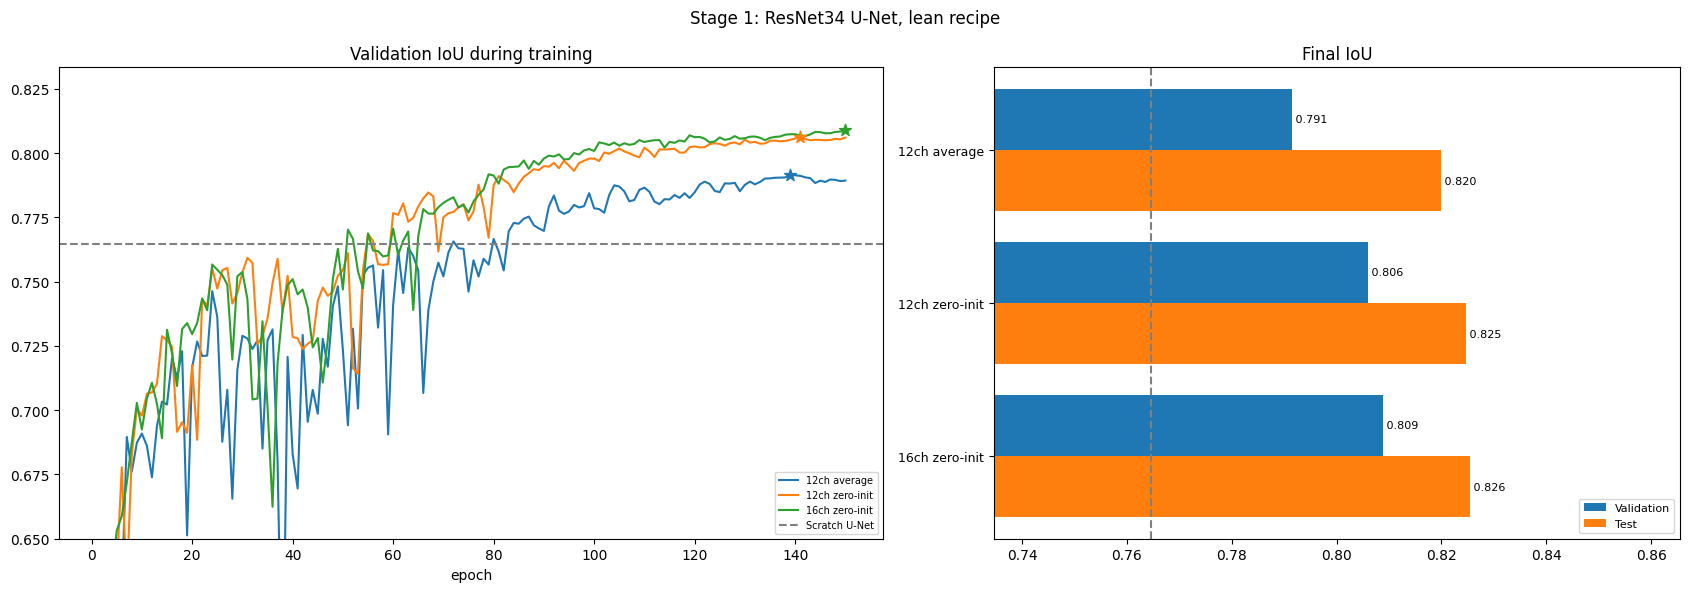

best input: 16ch zero-init


In [9]:
stage1 = {}
for inp in INPUTS:
    stage1[inp["name"]] = train({"encoder": "resnet34", **inp}, LEAN, inp["name"])

plot_stage(stage1, "Stage 1: ResNet34 U-Net, lean recipe")
base_label = max(stage1, key=lambda k: stage1[k]["val"]["iou"])
base = stage1[base_label]
print("best input:", base_label)

## 10. Stage 2: recipe build-up

Starting from the best Stage 1 model (BCE + Dice loss), each step adds one technique on top of the current best model and is kept only if validation IoU improves. Every run trains for a fixed 150 epochs with a cosine schedule (no early stopping) and keeps the best epoch by validation IoU.

+ Tversky loss | epoch   1 | train loss 1.350 acc 0.620 F1 0.513 | val loss 1.551 acc 0.467 F1 0.494 IoU 0.328
+ Tversky loss | epoch  25 | train loss 0.553 acc 0.921 F1 0.852 | val loss 0.595 acc 0.913 F1 0.846 IoU 0.733
+ Tversky loss | epoch  50 | train loss 0.400 acc 0.933 F1 0.874 | val loss 0.468 acc 0.920 F1 0.860 IoU 0.755
+ Tversky loss | epoch  75 | train loss 0.340 acc 0.945 F1 0.892 | val loss 0.439 acc 0.932 F1 0.878 IoU 0.783
+ Tversky loss | epoch 100 | train loss 0.283 acc 0.952 F1 0.908 | val loss 0.398 acc 0.937 F1 0.887 IoU 0.797
+ Tversky loss | epoch 125 | train loss 0.263 acc 0.957 F1 0.916 | val loss 0.388 acc 0.941 F1 0.893 IoU 0.806
+ Tversky loss | epoch 150 | train loss 0.258 acc 0.958 F1 0.919 | val loss 0.388 acc 0.941 F1 0.894 IoU 0.808
+ Tversky loss | best epoch 141 | val IoU 0.8093 | test IoU 0.8321

+ attention + EMA | epoch   1 | train loss 1.371 acc 0.603 F1 0.497 | val loss 1.537 acc 0.557 F1 0.527 IoU 0.358
+ attention + EMA | epoch  25 | train los

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

+ ResNet50 encoder | epoch   1 | train loss 1.361 acc 0.538 F1 0.497 | val loss 2.413 acc 0.441 F1 0.488 IoU 0.323
+ ResNet50 encoder | epoch  25 | train loss 0.480 acc 0.932 F1 0.869 | val loss 0.540 acc 0.912 F1 0.851 IoU 0.740
+ ResNet50 encoder | epoch  50 | train loss 0.343 acc 0.944 F1 0.890 | val loss 0.472 acc 0.927 F1 0.868 IoU 0.767
+ ResNet50 encoder | epoch  75 | train loss 0.268 acc 0.958 F1 0.917 | val loss 0.398 acc 0.945 F1 0.901 IoU 0.820
+ ResNet50 encoder | epoch 100 | train loss 0.235 acc 0.964 F1 0.929 | val loss 0.396 acc 0.942 F1 0.897 IoU 0.814
+ ResNet50 encoder | epoch 125 | train loss 0.211 acc 0.967 F1 0.937 | val loss 0.397 acc 0.946 F1 0.903 IoU 0.823
+ ResNet50 encoder | epoch 150 | train loss 0.204 acc 0.969 F1 0.940 | val loss 0.397 acc 0.948 F1 0.905 IoU 0.827
+ ResNet50 encoder | best epoch 150 | val IoU 0.8269 | test IoU 0.8466

kept: ['baseline (16ch zero-init)', '+ Tversky loss', '+ 2x input upscaling', '+ ResNet50 encoder']
dropped: ['+ attention 

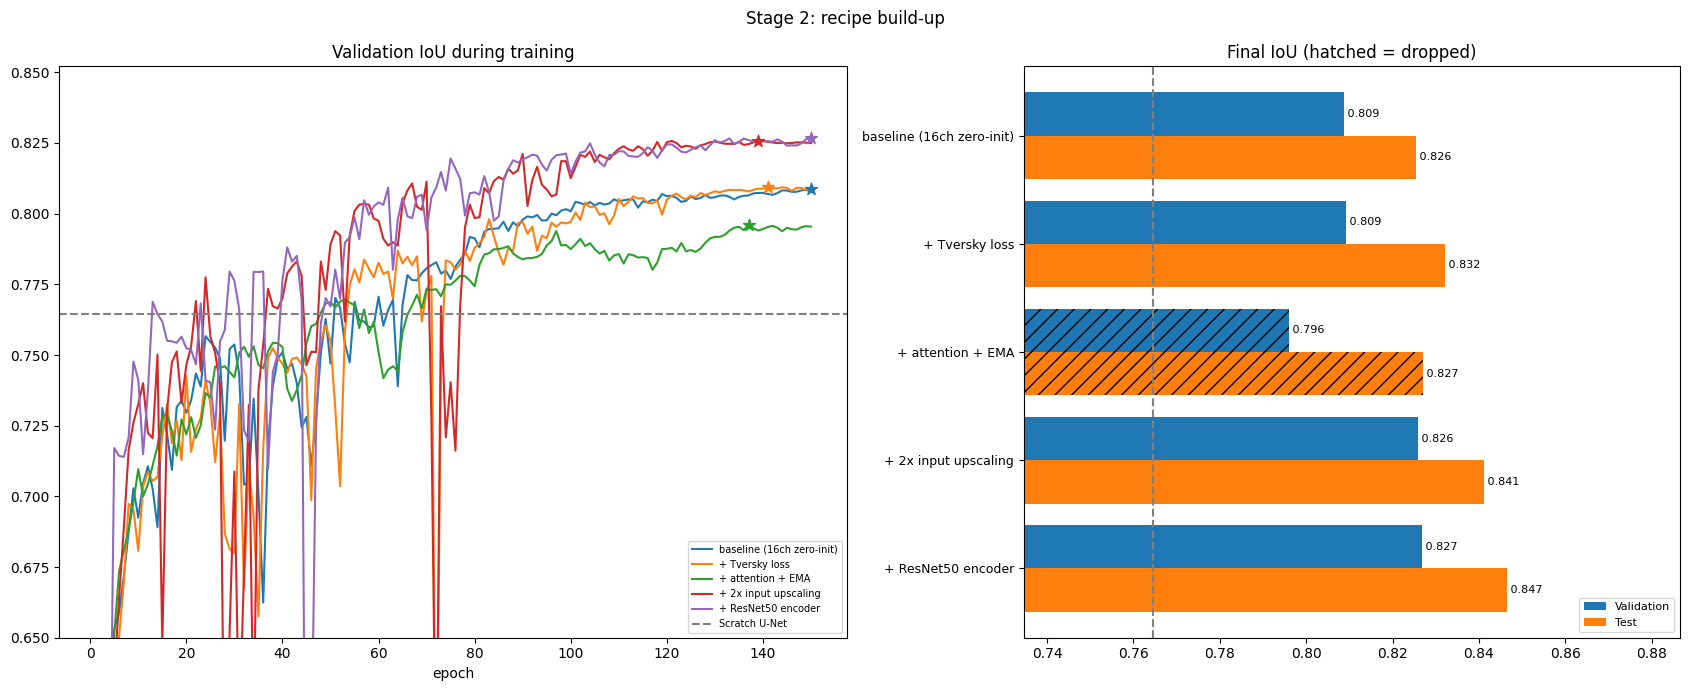

In [10]:
stage2 = {f"baseline ({base_label})": base}
kept = {f"baseline ({base_label})": True}
best = base
for label, cfg_update, recipe_update in STEPS:
    run = train({**best["cfg"], **cfg_update}, {**best["recipe"], **recipe_update}, label)
    stage2[label] = run
    kept[label] = run["val"]["iou"] > best["val"]["iou"]
    if kept[label]:
        best = run

final = best
print("kept:", [l for l in kept if kept[l]])
print("dropped:", [l for l in kept if not kept[l]])
plot_stage(stage2, "Stage 2: recipe build-up", kept)

## 11. Final model: training trace

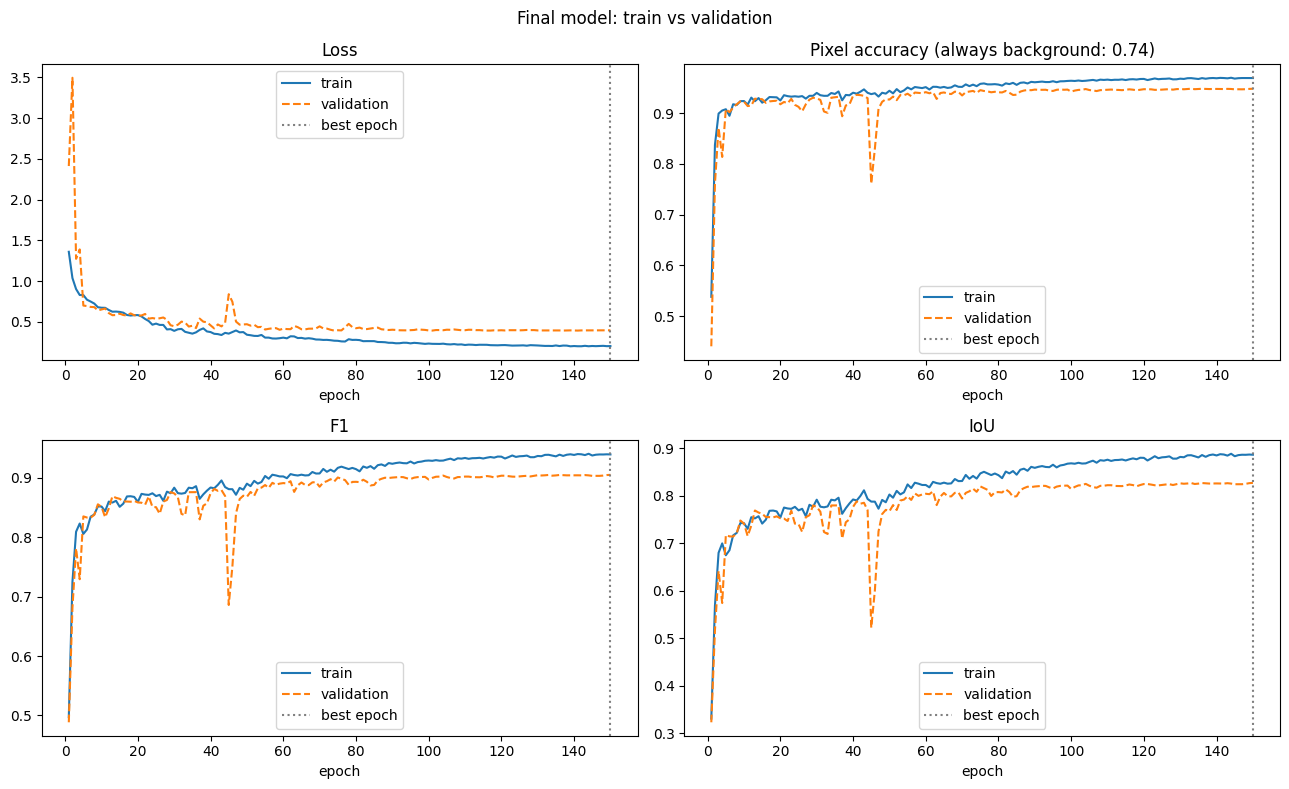

In [11]:
plot_trace(final, "Final model: train vs validation")

## 12. Test-time augmentation and seed stability

In [12]:
def predict_tta(model, indices, channels):
    x = torch.from_numpy(X[np.ix_(indices, channels)])
    total = 0
    for flip in (False, True):
        for k in range(4):
            t = torch.rot90(x.flip(3) if flip else x, k, (2, 3))
            p = torch.rot90(torch.from_numpy(predict_tensor(model, t)), -k, (1, 2))
            total = total + (p.flip(2) if flip else p)
    return (total / 8).numpy()


final_tta = {"val": metrics(predict_tta(final["model"], val_idx, final["channels"]), gt_val),
             "test": metrics(predict_tta(final["model"], test_idx, final["channels"]), gt_test)}

seed_runs = [final] + [train(final["cfg"], final["recipe"], f"seed {sd}", sd) for sd in SEEDS_EXTRA]
for split in ("val", "test"):
    v = [r[split]["iou"] for r in seed_runs]
    print(f"{split} IoU over {len(seed_runs)} seeds: {np.mean(v):.4f} ± {np.std(v):.4f}")

seed 43 | epoch   1 | train loss 1.293 acc 0.690 F1 0.541 | val loss 1.715 acc 0.679 F1 0.611 IoU 0.440
seed 43 | epoch  25 | train loss 0.482 acc 0.920 F1 0.853 | val loss 0.545 acc 0.901 F1 0.834 IoU 0.715
seed 43 | epoch  50 | train loss 0.370 acc 0.939 F1 0.881 | val loss 0.436 acc 0.940 F1 0.889 IoU 0.800
seed 43 | epoch  75 | train loss 0.272 acc 0.955 F1 0.913 | val loss 0.418 acc 0.944 F1 0.897 IoU 0.813
seed 43 | epoch 100 | train loss 0.237 acc 0.963 F1 0.927 | val loss 0.388 acc 0.948 F1 0.905 IoU 0.826
seed 43 | epoch 125 | train loss 0.212 acc 0.966 F1 0.935 | val loss 0.382 acc 0.948 F1 0.906 IoU 0.828
seed 43 | epoch 150 | train loss 0.208 acc 0.968 F1 0.936 | val loss 0.380 acc 0.949 F1 0.908 IoU 0.831
seed 43 | best epoch 136 | val IoU 0.8322 | test IoU 0.8462

seed 44 | epoch   1 | train loss 1.279 acc 0.725 F1 0.497 | val loss 1.202 acc 0.757 F1 0.662 IoU 0.495
seed 44 | epoch  25 | train loss 0.396 acc 0.935 F1 0.874 | val loss 0.483 acc 0.919 F1 0.856 IoU 0.748
see

## 13. Comparison with the scratch U-Net

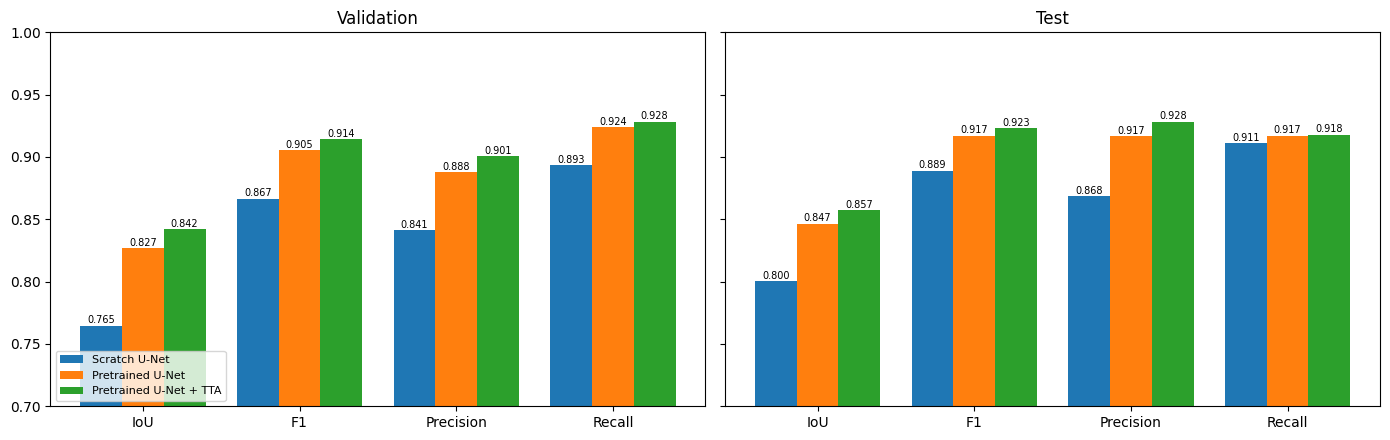

validation IoU 0.8269 vs scratch U-Net 0.7646 (delta +0.0623), higher than scratch U-Net: yes

| Model | Val IoU | Val F1 | Val Precision | Val Recall | Test IoU | Test F1 | Test Precision | Test Recall |
|---|---|---|---|---|---|---|---|---|
| Scratch U-Net | 0.7646 | 0.8666 | 0.8413 | 0.8934 | 0.8004 | 0.8891 | 0.8684 | 0.9109 |
| Pretrained U-Net | 0.8269 | 0.9053 | 0.8876 | 0.9237 | 0.8466 | 0.9169 | 0.9167 | 0.9171 |
| Pretrained U-Net + TTA | 0.8420 | 0.9142 | 0.9005 | 0.9283 | 0.8571 | 0.9230 | 0.9284 | 0.9177 |


In [13]:
models = {
    "Scratch U-Net": SCRATCH,
    "Pretrained U-Net": {"val": final["val"], "test": final["test"]},
    "Pretrained U-Net + TTA": final_tta,
}
keys = ["iou", "f1", "precision", "recall"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
width = 0.8 / len(models)
for ax, split in zip(axes, ("val", "test")):
    for i, (name, m) in enumerate(models.items()):
        vals = [m[split][k] for k in keys]
        bars = ax.bar(np.arange(4) + i * width - 0.4 + width / 2, vals, width, label=name, color=COLORS[i])
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.002, f"{v:.3f}", ha="center", fontsize=7)
    ax.set_xticks(range(4))
    ax.set_xticklabels(["IoU", "F1", "Precision", "Recall"])
    ax.set_ylim(0.7, 1.0)
    ax.set_title("Validation" if split == "val" else "Test")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

delta = final["val"]["iou"] - SCRATCH["val"]["iou"]
print(f"validation IoU {final['val']['iou']:.4f} vs scratch U-Net {SCRATCH['val']['iou']:.4f} (delta {delta:+.4f}), higher than scratch U-Net: {'yes' if delta > 0 else 'no'}\n")

print("| Model | Val IoU | Val F1 | Val Precision | Val Recall | Test IoU | Test F1 | Test Precision | Test Recall |\n|---|---|---|---|---|---|---|---|---|")
for name, m in models.items():
    print(f"| {name} | " + " | ".join(f"{m[s][k]:.4f}" for s in ("val", "test") for k in keys) + " |")

## 14. Analysis of the final model

  0%|          | 0/16 [00:00<?, ?it/s]

test IoU 0.8466 | with all ancillary channels zeroed 0.8100


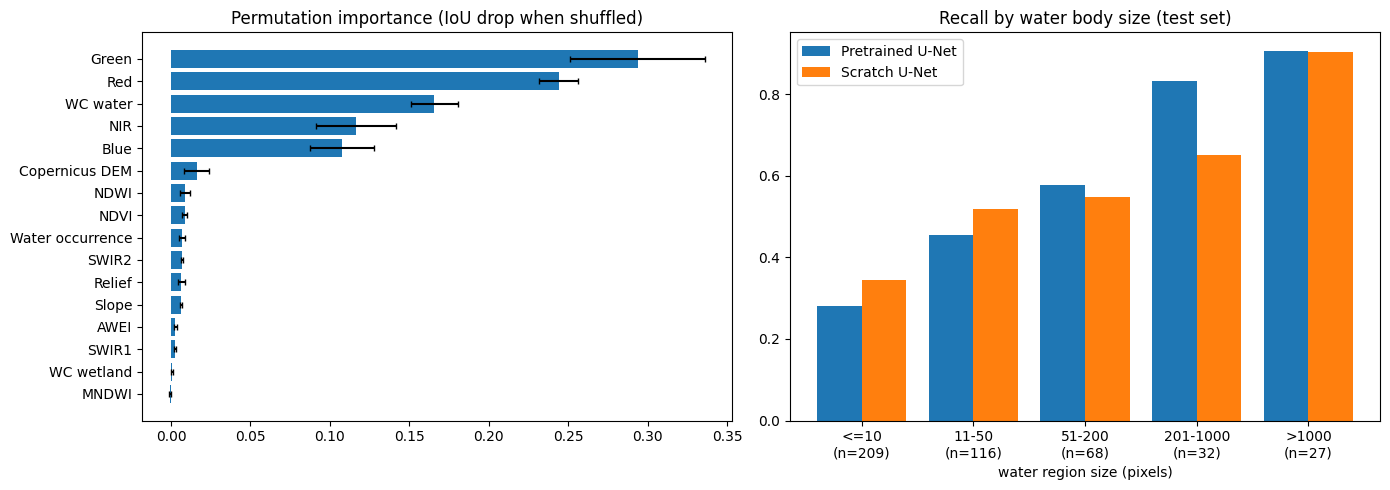

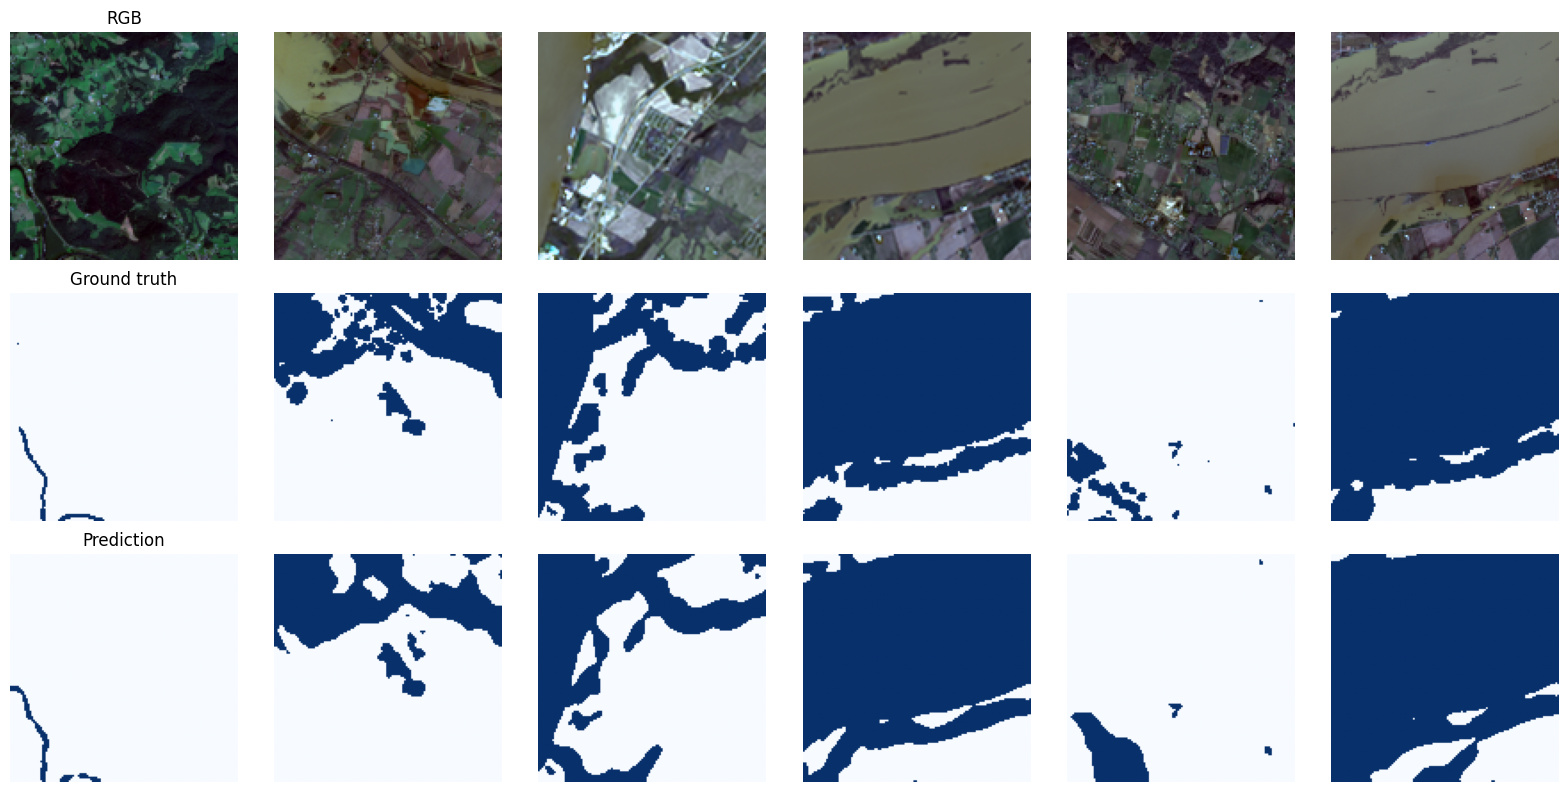

In [14]:
channels = final["channels"]
names = [NAMES[c] for c in channels]
x = torch.from_numpy(X[np.ix_(test_idx, channels)])

base_iou = metrics(predict_tensor(final["model"], x), gt_test)["iou"]
g = torch.Generator().manual_seed(0)
drops = np.zeros((len(channels), 3))
for j in tqdm(range(len(channels))):
    for r in range(3):
        xp = x.clone()
        xp[:, j] = x[torch.randperm(len(x), generator=g), j]
        drops[j, r] = base_iou - metrics(predict_tensor(final["model"], xp), gt_test)["iou"]

xz = x.clone()
xz[:, [j for j, c in enumerate(channels) if NAMES[c] in ANCILLARY]] = 0
print(f"test IoU {base_iou:.4f} | with all ancillary channels zeroed {metrics(predict_tensor(final['model'], xz), gt_test)['iou']:.4f}")

pred_test = final["pt"] > 0.5
sizes, recalls = [], []
for i in range(len(gt_test)):
    lab, n = cc_label(gt_test[i])
    for k in range(1, n + 1):
        region = lab == k
        sizes.append(int(region.sum()))
        recalls.append(pred_test[i][region].mean())
sizes, recalls = np.array(sizes), np.array(recalls)
bin_id = np.digitize(sizes, [10, 50, 200, 1000], right=True)

n_panels = 3 if final["recipe"]["attention"] else 2
fig, axes = plt.subplots(1, n_panels, figsize=(7 * n_panels, 5))
order = np.argsort(drops.mean(1))
axes[0].barh([names[i] for i in order], drops.mean(1)[order], xerr=drops.std(1)[order], capsize=2)
axes[0].set_title("Permutation importance (IoU drop when shuffled)")

axes[1].bar(np.arange(5) - 0.2, [recalls[bin_id == b].mean() for b in range(5)], 0.4, label="Pretrained U-Net")
axes[1].bar(np.arange(5) + 0.2, list(SCRATCH_RECALL_BY_SIZE.values()), 0.4, label="Scratch U-Net")
axes[1].set_xticks(range(5))
axes[1].set_xticklabels([f"{l}\n(n={(bin_id == b).sum()})" for b, l in enumerate(SCRATCH_RECALL_BY_SIZE)])
axes[1].set_xlabel("water region size (pixels)")
axes[1].set_title("Recall by water body size (test set)")
axes[1].legend()

if final["recipe"]["attention"]:
    with torch.no_grad():
        final["model"].eval()
        w = torch.cat([final["model"].attn.fc(b.to(device).mean(dim=(2, 3))).cpu() for b in x.split(BATCH_SIZE)]).numpy()
    order = np.argsort(w.mean(0))
    axes[2].barh([names[i] for i in order], w.mean(0)[order], xerr=w.std(0)[order], capsize=2)
    axes[2].set_xlim(0, 1)
    axes[2].set_title("Learned channel attention (mean gate)")
plt.tight_layout()
plt.show()

xb, yb = next(iter(make_loader(test_idx[:6], channels, False)))
pred = predict_tensor(final["model"], xb) > 0.5
fig, axes = plt.subplots(3, 6, figsize=(16, 8))
for j in range(len(xb)):
    rgb = X[test_idx[j], [3, 2, 1]].transpose(1, 2, 0)
    axes[0, j].imshow((rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6))
    axes[1, j].imshow(yb[j, 0], cmap="Blues")
    axes[2, j].imshow(pred[j], cmap="Blues")
for ax in axes.flat:
    ax.axis("off")
axes[0, 0].set_title("RGB")
axes[1, 0].set_title("Ground truth")
axes[2, 0].set_title("Prediction")
plt.tight_layout()
plt.show()

torch.save(final["model"].state_dict(), "best_pretrained_model.pt")
pd.concat({n: r["history"] for n, r in {**stage1, **stage2}.items()}, names=["model"]).to_csv("training_histories.csv")

The pretrained encoder brings edge and texture filters that are useful from the first epoch, so water boundaries are learned from 214 images far more easily than from random weights. It is also deeper, with residual connections that ease optimisation and a larger receptive field for separating shadows from water. Part of the gain over the scratch U-Net also comes from training longer and from rotation augmentation, because the scratch U-Net had not converged at 100 epochs. Small water bodies remain the weak spot (Section 14).